# Notebook 4 — Exploratory Anomaly Detection

## Purpose

Use interpretable domain checks and an unsupervised Isolation Forest to flag unusual profiles in the synthetic loan-application dataset. The detector uses borrower, loan, and credit characteristics only: the default outcome, application ID, duplicate exposure assumption, prior-default history, repayment method, and loss assumption are excluded from anomaly scoring.

**Important:** an anomaly score measures how unusual a profile is relative to this dataset. It is **not** a delinquency probability, fraud determination, or recommendation to reject an application. Review flags against business rules and source records. This notebook is exploratory and does not establish that anomaly detection improves classification.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

relative_data_path = Path("data/raw/finsight_ai_india_synthetic_5000.csv")
data_path = next(
    (path for path in (relative_data_path, Path("..") / relative_data_path) if path.exists()),
    None,
)
if data_path is None:
    raise FileNotFoundError(
        "Could not find data/raw/finsight_ai_india_synthetic_5000.csv. "
        "Run this notebook from the project root or notebooks/ directory."
    )

df = pd.read_csv(data_path)
target_column = "target_default_within_12m"
if target_column not in df.columns:
    raise ValueError(f"Expected outcome column {target_column!r} was not found.")
if df[target_column].isna().any() or not df[target_column].isin([0, 1]).all():
    raise ValueError("The observed outcome must contain complete binary labels for descriptive comparisons.")
if df["monthly_net_income_inr"].isna().any() or df["monthly_net_income_inr"].le(0).any():
    raise ValueError("Monthly net income must be positive to calculate loan-to-annual-income ratio.")

print(f"Source: {data_path.resolve()}")
print(f"Applications: {len(df):,}; outcome positives: {df[target_column].sum():,} ({df[target_column].mean():.1%})")
print("\nDomain checks use stated field definitions; a statistical flag alone does not establish invalidity.")

domain_rules = {
    "Employment duration exceeds applicant age": df["employment_years"].gt(df["age_years"]),
    "Employment duration is negative": df["employment_years"].lt(0),
    "Credit history exceeds applicant age": df["credit_history_years"].gt(df["age_years"]),
    "Credit history is negative": df["credit_history_years"].lt(0),
    "Credit utilization is negative": df["credit_utilization_ratio"].lt(0),
    "Credit utilization exceeds 100%": df["credit_utilization_ratio"].gt(1),
    "Debt-to-income ratio is negative": df["debt_to_income_after_loan"].lt(0),
}
domain_review = pd.DataFrame(
    {
        "flagged_rows": {name: int(mask.sum()) for name, mask in domain_rules.items()},
        "missing_values_in_field": {
            name: int(df.loc[mask.index, field].isna().sum())
            for (name, mask), field in zip(
                domain_rules.items(),
                [
                    "employment_years",
                    "employment_years",
                    "credit_history_years",
                    "credit_history_years",
                    "credit_utilization_ratio",
                    "credit_utilization_ratio",
                    "debt_to_income_after_loan",
                ],
            )
        },
    }
)
display(domain_review)
print(f"\nRows with at least one of these domain-rule flags: {int(pd.DataFrame(domain_rules).any(axis=1).sum()):,}")

Source: D:\GOURAB DAS\CODE\Git\FinSight AI\data\raw\finsight_ai_india_synthetic_5000.csv
Applications: 5,000; outcome positives: 1,384 (27.7%)

Domain checks use stated field definitions; a statistical flag alone does not establish invalidity.


,flagged_rows,missing_values_in_field
Employment duration exceeds applicant age,10,184
Employment duration is negative,0,184
Credit history exceeds applicant age,0,224
Credit history is negative,0,224
Credit utilization is negative,0,211
Credit utilization exceeds 100%,1,211
Debt-to-income ratio is negative,0,0



Rows with at least one of these domain-rule flags: 11


The earlier data audit found 10 applications where employment duration exceeds applicant age and one utilization ratio above 1. The checks above independently count those and related logically impossible values; missing values are not interpreted as invalid. Utilization over 100% can be legitimate when a credit line is over-limit, so it remains a review flag—not an automatic correction. Extreme but plausible debt-to-income ratios are not classified as invalid by a simple cutoff.

## 1. Fit Isolation Forest without using the outcome

The unsupervised feature set contains numeric application information and selected nominal profile fields. A transparent loan-to-annual-income ratio is calculated from principal and verified positive monthly income. Numeric missing values are median-imputed with missingness indicators and robust-scaled; missing categories receive a dedicated level, and the categorical fields are one-hot encoded.

`contamination=0.02` is an explicit **review-list sizing assumption**: it asks the algorithm to flag approximately the most unusual 2% of these profiles. It is not an empirically validated anomaly prevalence. Since this is an exploratory descriptive fit, the detector is fit to all available feature rows, without labels; its flags are not used to train or evaluate a default model.

In [2]:
numeric_features = [
    "age_years",
    "employment_years",
    "monthly_net_income_inr",
    "existing_monthly_debt_inr",
    "requested_loan_amount_inr",
    "loan_tenure_months",
    "annual_interest_rate_pct",
    "estimated_emi_inr",
    "debt_to_income_after_loan",
    "credit_history_years",
    "open_credit_accounts",
    "credit_inquiries_last_6m",
    "late_payments_last_12m",
    "credit_utilization_ratio",
    "savings_balance_inr",
    "banking_relationship_months",
    "dependents_count",
]
categorical_features = ["state", "city_tier", "employment_type", "education_level", "residence_type", "loan_purpose"]
excluded_from_anomaly_features = {
    "application_id": "record identifier",
    target_column: "outcome label; intentionally excluded from unsupervised fitting and scoring",
    "prior_default_flag": "outcome observation window is undocumented",
    "repayment_method": "may reflect post-application behavior",
    "ead_assumption_inr": "duplicates requested_loan_amount_inr",
    "lgd_assumption": "unverified loss scenario assumption",
}
anomaly_features = numeric_features + categorical_features
if set(anomaly_features).intersection(excluded_from_anomaly_features):
    raise ValueError("An excluded identifier, target, or uncertain-timing field entered the detector feature list.")
missing_anomaly_features = set(anomaly_features).difference(df.columns)
if missing_anomaly_features:
    raise ValueError(f"Expected anomaly features are missing: {sorted(missing_anomaly_features)}")

X_anomaly = df[anomaly_features].copy()
X_anomaly["requested_loan_to_annual_income"] = (
    df["requested_loan_amount_inr"] / (12 * df["monthly_net_income_inr"])
)
df["requested_loan_to_annual_income"] = X_anomaly["requested_loan_to_annual_income"]
numeric_features = numeric_features + ["requested_loan_to_annual_income"]
anomaly_features = numeric_features + categorical_features
assert target_column not in X_anomaly.columns

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", RobustScaler()),
    ]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)
anomaly_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    sparse_threshold=0,
)

contamination_rate = 0.02
anomaly_pipeline = Pipeline(
    steps=[
        ("preprocessor", anomaly_preprocessor),
        (
            "isolation_forest",
            IsolationForest(
                n_estimators=300,
                contamination=contamination_rate,
                max_samples="auto",
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)
anomaly_pipeline.fit(X_anomaly)

# Higher values indicate greater unusualness; these are not probabilities.
df["anomaly_score"] = -anomaly_pipeline.decision_function(X_anomaly)
df["isolation_forest_flag"] = anomaly_pipeline.predict(X_anomaly) == -1
anomaly_count = int(df["isolation_forest_flag"].sum())
print(f"Rows used to fit the unsupervised detector: {len(X_anomaly):,}")
print(f"Outcome column included in detector input: {target_column in X_anomaly.columns}")
print(f"Selected review-list size (contamination={contamination_rate:.0%}): {anomaly_count:,} ({anomaly_count / len(df):.1%})")
print("Anomaly score direction: larger scores indicate more unusual profiles; no score is a default probability.")
print(f"Encoded feature count supplied to Isolation Forest: {anomaly_pipeline.named_steps['preprocessor'].transform(X_anomaly.iloc[:1]).shape[1]}")

Rows used to fit the unsupervised detector: 5,000
Outcome column included in detector input: False
Selected review-list size (contamination=2%): 100 (2.0%)
Anomaly score direction: larger scores indicate more unusual profiles; no score is a default probability.
Encoded feature count supplied to Isolation Forest: 68


Isolation Forest operates on robust-scaled numeric fields and one-hot encoded categories; missingness is retained as signal instead of dropping incomplete applications. The outcome is excluded from fitting and scoring. At a 2% contamination setting, the flagged share is a chosen review-list size—not a claim that 2% of applicants are truly anomalous, fraudulent, or likely to default.

## 2. Inspect highest-scoring profiles and domain consistency

Review the most unusual profiles alongside their input values, missing fields, and independent domain-rule flags. Scores are ordered for prioritizing manual review only. A high score alone does not justify a correction or exclusion.

In [3]:
domain_flag_table = pd.DataFrame(domain_rules)
df["domain_rule_flag_count"] = domain_flag_table.sum(axis=1).astype(int)
df["has_domain_rule_flag"] = df["domain_rule_flag_count"].gt(0)
df["missing_feature_count"] = X_anomaly[anomaly_features].isna().sum(axis=1)

profile_columns = [
    "application_id",
    "age_years",
    "employment_type",
    "employment_years",
    "monthly_net_income_inr",
    "requested_loan_amount_inr",
    "estimated_emi_inr",
    "debt_to_income_after_loan",
    "requested_loan_to_annual_income",
    "credit_history_years",
    "credit_utilization_ratio",
    "state",
    "missing_feature_count",
    "domain_rule_flag_count",
    "anomaly_score",
    "isolation_forest_flag",
]
top_profiles = df.nlargest(15, "anomaly_score")[profile_columns].copy()
print("Fifteen highest-scoring profiles for manual review (not fraud/default predictions):")
display(top_profiles.round({"debt_to_income_after_loan": 3, "requested_loan_to_annual_income": 3, "credit_utilization_ratio": 3, "anomaly_score": 4}))

review_summary = pd.DataFrame(
    {
        "applications": [int(df["isolation_forest_flag"].sum()), int(df["has_domain_rule_flag"].sum())],
        "percent_of_dataset": [100 * df["isolation_forest_flag"].mean(), 100 * df["has_domain_rule_flag"].mean()],
        "median_missing_features": [
            df.loc[df["isolation_forest_flag"], "missing_feature_count"].median(),
            df.loc[df["has_domain_rule_flag"], "missing_feature_count"].median(),
        ],
    },
    index=["Isolation Forest review flags", "At least one domain-rule flag"],
)
print("Compare unsupervised and deterministic review queues:")
display(review_summary.round(2))
print(f"Applications flagged both by Isolation Forest and domain rules: {(df['isolation_forest_flag'] & df['has_domain_rule_flag']).sum():,}")

Fifteen highest-scoring profiles for manual review (not fraud/default predictions):


,application_id,age_years,employment_type,employment_years,monthly_net_income_inr,requested_loan_amount_inr,estimated_emi_inr,debt_to_income_after_loan,requested_loan_to_annual_income,credit_history_years,credit_utilization_ratio,state,missing_feature_count,domain_rule_flag_count,anomaly_score,isolation_forest_flag
421,FIN000422,56,Agriculture,8.4,7408,1128603,194666,26.529,12.696,7.9,0.856,West Bengal,0,0,0.0442,True
587,FIN000588,25,Unemployed,0.0,6818,1059743,187545,27.730,12.953,5.9,0.229,Delhi NCR,0,0,0.0411,True
992,FIN000993,33,Unemployed,0.0,5757,780355,45973,8.189,11.296,1.1,NaN,Assam,1,0,0.0409,True
2695,FIN002696,28,Agriculture,11.3,5000,619680,33347,6.902,10.328,2.8,0.096,Delhi NCR,1,0,0.0339,True
3992,FIN003993,33,Unemployed,NaN,11481,1489131,93531,8.432,10.809,5.9,0.427,Karnataka,1,0,0.0304,True
3668,FIN003669,26,Unemployed,0.0,5000,282689,11506,2.344,4.711,NaN,0.260,Maharashtra,1,0,0.0287,True
3004,FIN003005,24,Business owner,5.6,398564,671044,63994,0.563,0.140,6.0,0.238,Punjab,0,0,0.0272,True
2499,FIN002500,62,Gig/Contract,3.7,29906,1174599,114000,4.314,3.273,4.2,0.792,Rajasthan,0,0,0.0263,True
1934,FIN001935,31,Unemployed,0.0,6147,1298560,36869,6.121,17.604,6.7,0.226,Telangana,0,0,0.0246,True
1375,FIN001376,54,Agriculture,2.7,17384,1155467,59858,4.000,5.539,NaN,0.330,Karnataka,1,0,0.0241,True


Compare unsupervised and deterministic review queues:


,applications,percent_of_dataset,median_missing_features
Isolation Forest review flags,100,2.00,1.0
At least one domain-rule flag,11,0.22,0.0


Applications flagged both by Isolation Forest and domain rules: 0


The ranked table lets a reviewer check unusual combinations against the feature definitions: for example, employment history longer than age is a logical inconsistency to verify, while a large loan, high debt ratio, missing credit history, or over-limit credit utilization might have a valid explanation. Agreement with a domain flag is useful for triage, but disagreement is also informative: Isolation Forest detects combinations and category patterns beyond the rules we wrote. The ID is shown only to locate source records; it never enters the detector.

## 3. Visualize review flags and inspect the outcome separately

The profile plot displays selected underwriting dimensions and highlights detector-flagged rows. The separate outcome chart compares observed default prevalence across flagged and unflagged groups **after** unsupervised scoring; target labels never influence the preprocessing, fit, score, or threshold. These descriptive rates are not individual predictions and do not validate utility.

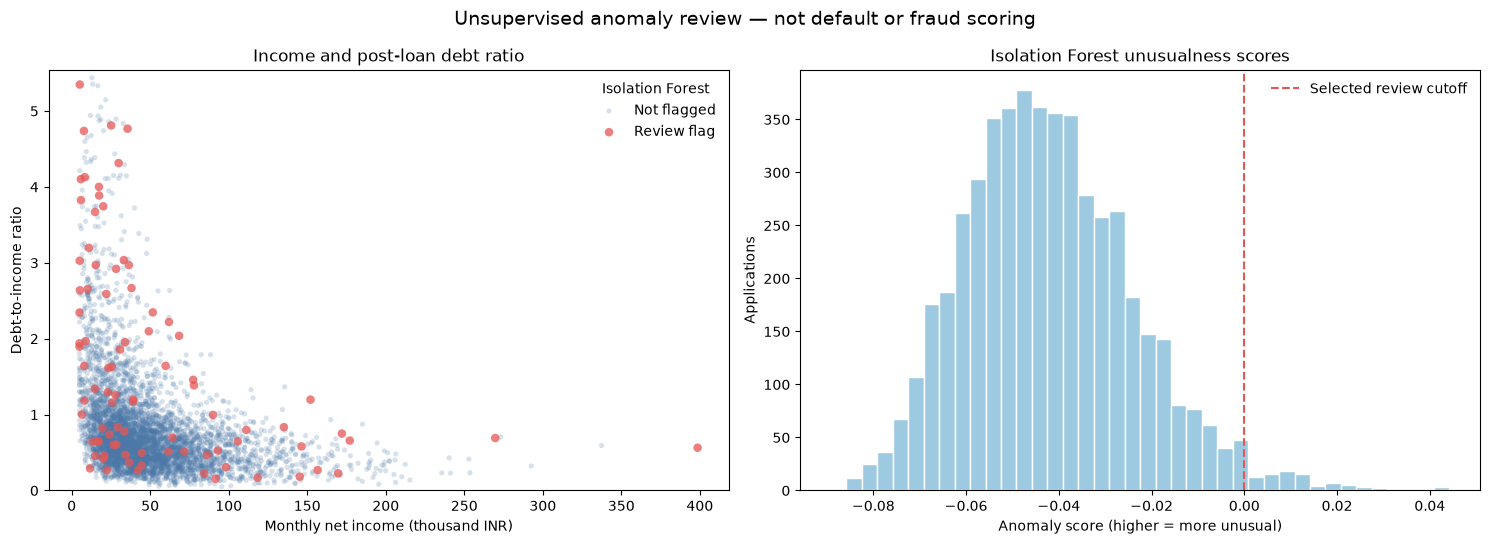

Post-fit descriptive comparison with the observed label (not used by the detector):


,applications,observed_defaults,observed_default_rate_percent
isolation_forest_flag,,,
Not flagged,4900,1332,27.18
Isolation Forest flag,100,52,52.00


A group default rate is not a calibrated individual probability and does not establish a fraud or lending rule.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
flag_colors = {False: "#4C78A8", True: "#E45756"}
for flag, group in df.groupby("isolation_forest_flag", observed=True):
    axes[0].scatter(
        group["monthly_net_income_inr"] / 1000,
        group["debt_to_income_after_loan"],
        color=flag_colors[bool(flag)],
        label="Review flag" if flag else "Not flagged",
        alpha=0.75 if flag else 0.22,
        s=38 if flag else 14,
        edgecolors="none",
    )
axes[0].set_title("Income and post-loan debt ratio")
axes[0].set_xlabel("Monthly net income (thousand INR)")
axes[0].set_ylabel("Debt-to-income ratio")
axes[0].legend(title="Isolation Forest", frameon=False)
axes[0].set_ylim(0, min(df["debt_to_income_after_loan"].quantile(0.99) * 1.25, df["debt_to_income_after_loan"].max()))

axes[1].hist(df["anomaly_score"], bins=40, color="#9ECAE1", edgecolor="white")
axes[1].axvline(
    df.loc[df["isolation_forest_flag"], "anomaly_score"].min(),
    color="#E45756",
    linestyle="--",
    linewidth=1.5,
    label="Selected review cutoff",
)
axes[1].set_title("Isolation Forest unusualness scores")
axes[1].set_xlabel("Anomaly score (higher = more unusual)")
axes[1].set_ylabel("Applications")
axes[1].legend(frameon=False)
fig.suptitle("Unsupervised anomaly review — not default or fraud scoring", fontsize=14)
fig.tight_layout()
plt.show()

outcome_comparison = (
    df.groupby("isolation_forest_flag", observed=True)[target_column]
    .agg(applications="size", observed_defaults="sum", observed_default_rate="mean")
    .rename(index={False: "Not flagged", True: "Isolation Forest flag"})
)
outcome_comparison["observed_default_rate_percent"] = 100 * outcome_comparison["observed_default_rate"]
print("Post-fit descriptive comparison with the observed label (not used by the detector):")
display(outcome_comparison[["applications", "observed_defaults", "observed_default_rate_percent"]].round(2))
print("A group default rate is not a calibrated individual probability and does not establish a fraud or lending rule.")

Points highlighted in red are unusual under the fitted feature-space model, not necessarily incorrect; visible concentration around an extreme ratio can help prioritize source verification. The default-rate table is deliberately descriptive and calculated only after the outcome-blind fit. Any difference between the two groups is not proof of predictive benefit, and no anomaly flag should be interpreted as a default chance or fraud allegation.

## Anomaly Detection Summary

### Q&A

- **Did an unsupervised method add exploratory value?** Isolation Forest produced a prioritized review list from numeric and nominal application features, alongside independent business-rule checks. The review list describes unusual profiles relative to this synthetic sample; it does not identify fraud or estimate delinquency.
- **Does this module improve default prediction?** That has not been tested or demonstrated. The detector is exploratory only; its flags should not be added as model predictors unless a separate, leakage-safe evaluation demonstrates incremental benefit on held-out data.

### Data Analysis Key Findings

- The observed default label and uncertain-time fields are excluded from anomaly model fitting, preprocessing, score calculation, and the review threshold. The label is compared with flags only after scoring for context.
- `contamination=0.02` controls a review-list size, not the true proportion of anomalous applicants. The top-scoring records are presented with source-field values, missingness, and rule flags to support manual review.
- Rule-based logical contradictions and statistical unusualness answer different questions: a domain violation calls for source verification, while a statistically rare but valid profile should not be automatically corrected or excluded.

### Insights or Next Steps

- Review flagged source records with a data owner and documented business rules; retain valid unusual cases and correct only verified source errors.
- Keep the module out of the default-decision pipeline unless a future leakage-safe, held-out comparison establishes additional value. Anomaly scores are neither delinquency probabilities nor fraud determinations, and this synthetic data is not evidence about real applicants.